In [1]:
import pandas as pd
import glob
import matplotlib.pyplot as plt

In [ ]:
files = sorted(glob.glob('../data/raw/*.csv'))
print(len(files))
demand = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

24


In [9]:
demand.head()

,REGION,SETTLEMENTDATE,TOTALDEMAND,RRP,PERIODTYPE
0,NSW1,2024/01/01 00:05:00,6574.92,57.98,TRADE
1,NSW1,2024/01/01 00:10:00,6651.09,70.27,TRADE
2,NSW1,2024/01/01 00:15:00,6538.96,57.98,TRADE
3,NSW1,2024/01/01 00:20:00,6497.99,54.95,TRADE
4,NSW1,2024/01/01 00:25:00,6404.55,54.95,TRADE


In [10]:
demand.shape

(210528, 5)

In [11]:
demand.info()

<class 'pandas.DataFrame'>
RangeIndex: 210528 entries, 0 to 210527
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   REGION          210528 non-null  str    
 1   SETTLEMENTDATE  210528 non-null  str    
 2   TOTALDEMAND     210528 non-null  float64
 3   RRP             210528 non-null  float64
 4   PERIODTYPE      210528 non-null  str    
dtypes: float64(2), str(3)
memory usage: 8.0 MB


In [ ]:
demand["SETTLEMENTDATE"] = pd.to_datetime(demand["SETTLEMENTDATE"])
demand = demand[["SETTLEMENTDATE", "TOTALDEMAND"]]
demand.info()

<class 'pandas.DataFrame'>
RangeIndex: 210528 entries, 0 to 210527
Data columns (total 2 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   SETTLEMENTDATE  210528 non-null  datetime64[us]
 1   TOTALDEMAND     210528 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 3.2 MB


In [13]:
daily = demand.set_index("SETTLEMENTDATE").resample("D").mean()

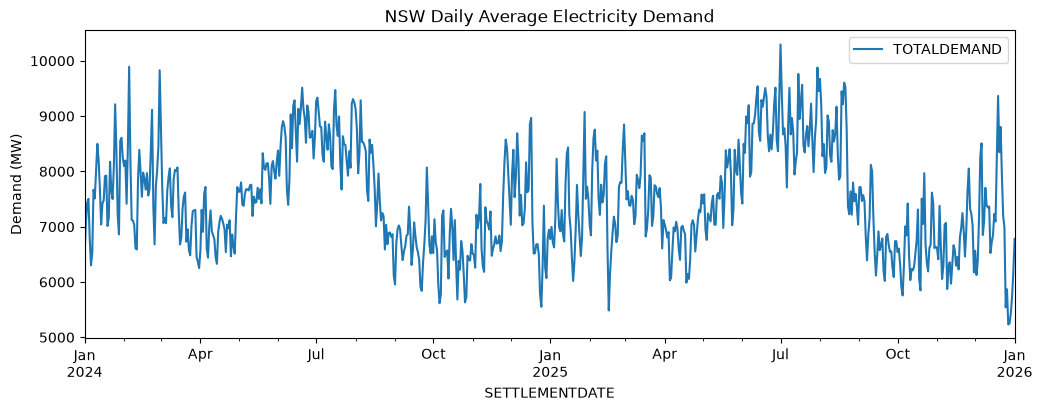

In [14]:
daily.plot(figsize=(12, 4), title="NSW Daily Average Electricity Demand")
plt.ylabel("Demand (MW)")
plt.show()